# Hyperparameter sweep — $\gamma \times K$ (3-month train / 1-month test, 30 restarts)

Monthly ritual: sweep the two knobs of the production pipeline (`stonks portfolio`) over the
**last 4 months** of top-500 daily returns — the **last 3 months fit**, the **last month is
held out** — and pick the configuration to gamble on the coming month.

For each $(\gamma, K)$:
1. factor-model $(\hat\mu, \Sigma_K)$ from the training window (rank-$K$ SVD + diagonal idio);
2. `N_RESTARTS=30` seeded restarts of the softmax gradient ascent (`lr=0.005`, 8000 iters —
   the CLI defaults); the **best restart by training objective** is the production pick, and
   **every restart is kept** (`keep_restarts=True`) for statistics;
3. each restart's frozen weights (after the `min_weight` cleanup + renormalization) are
   evaluated on the held-out month, giving a *distribution* of test profits per config:
   mean, std, min/max, and a t-stat-like $t = \bar{x}/(s/\sqrt{30})$.

Reading the stats: a config whose best restart looks great but whose 30-restart mean is
mediocre with a big std was **seed luck, not signal**. $t \gtrsim 2$ means the average
restart is distinguishable from zero; $t$ measures *restart* noise only — all 30 restarts
share the same test month, so window risk is untouched.

Anchors from the current CLI call: $\gamma = 40$, $K = 25$. Benchmarked against 1/N.

Runtime warning: ~70 s per config (30 restarts × 8000 iters); the default 6×5 grid takes
~35 min. Shrink `GAMMAS`/`KS` for a quicker pass.

*Not financial advice; single-window validation (see the honest-caveats cell at the end).*

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from stonks import get_prices, to_returns
from stonks.portfolio import _factor_covariance, _optimize_long_only

%matplotlib inline

## Parameters

In [2]:
TOP_N = 500
TRAIN_MONTHS = 3
TEST_MONTHS = 1
PERIOD = "2y"       # cached source; we slice the last TRAIN+TEST months

GAMMAS = [5, 10, 20, 40, 80, 160]   # risk aversion (anchor: 40)
KS = [3, 5, 10, 25, 40]             # SVD factors = denoising + concentration dial (anchor: 25)

N_RESTARTS = 30     # per (gamma, K): best-by-train-objective is the pick, all 30 feed the stats
LR = 0.005          # same as the CLI call
ITERS = 8000        # production default in _optimize_long_only
MIN_WEIGHT = 1e-3   # drop tiny weights, renormalize (matches optimize_portfolio)
SEED = 0            # restart r uses seed+r (deterministic)

## Fetch the 4-month window and split train / test

`dropna` on the whole window keeps only stocks with data across **both** periods, so train and
test use the same universe (same trick as `portfolio_oos_test`).

In [3]:
prices = get_prices(top_n=TOP_N, period=PERIOD, interval="1d", field="close")
last = pd.Timestamp(prices.columns[-1])
start = last - pd.DateOffset(months=TRAIN_MONTHS + TEST_MONTHS)
returns = to_returns(prices.loc[:, prices.columns >= start]).dropna()

test_start = last - pd.DateOffset(months=TEST_MONTHS)
train = returns.loc[:, returns.columns < test_start]
test = returns.loc[:, returns.columns >= test_start]

print(f"window ends {last.date()} | {returns.shape[0]} tickers | "
      f"train {train.shape[1]} days ({train.columns[0].date()}..{train.columns[-1].date()}) | "
      f"test {test.shape[1]} days ({test.columns[0].date()}..{test.columns[-1].date()})")

window ends 2026-10-20 | 499 tickers | train 62 days (2026-06-23..2026-09-18) | test 22 days (2026-09-21..2026-10-20)


## Sweep: 30 restarts per config, evaluated individually on the test month

$(\hat\mu, \Sigma_K)$ depend only on $K$, so they are computed **once per $K$** and reused
across all $\gamma$. Restart selection uses the **training objective only** — the test month
never touches the fit. Per config we keep: the best-restart metrics (what production would
hold) plus mean/std/min/max and a t-stat across all 30 restarts.

In [4]:
def perf(w, R):
    """(compounded profit, annualized vol, annualized Sharpe) of frozen weights w on R."""
    rp = w @ R
    profit = np.prod(1 + rp) - 1
    vol = rp.std() * np.sqrt(252)
    sharpe = rp.mean() / rp.std() * np.sqrt(252) if rp.std() > 0 else np.nan
    return profit, vol, sharpe


def clean_weights(w_raw, index):
    """min_weight filter + renormalize, sorted descending (optimize_portfolio's output)."""
    ws = pd.Series(w_raw, index=index)
    ws = ws[ws >= MIN_WEIGHT]
    return (ws / ws.sum()).sort_values(ascending=False)


def full_vector(ws, index):
    """Expand cleaned weights back to the full universe (0 for dropped names),
    so they can be matmul-ed against the N-row returns matrix."""
    return ws.reindex(index, fill_value=0.0).to_numpy()


rows = []
weights_by_cfg = {}
t_start = time.time()

for K in KS:
    mu, Sigma = _factor_covariance(train, K)
    for gamma in GAMMAS:
        w_raw, hists, restarts = _optimize_long_only(
            mu, Sigma, gamma, iters=ITERS, lr=LR, seed=SEED,
            n_restarts=N_RESTARTS, keep_restarts=True,
        )
        finals = [h[-1] for h in hists]
        w = clean_weights(w_raw, train.index)          # best restart by train objective
        weights_by_cfg[(K, gamma)] = w

        profits, sharpes, holds = [], [], []
        for w_restart in restarts:
            ws_r = clean_weights(w_restart, train.index)
            p, _, s = perf(full_vector(ws_r, train.index), test.to_numpy())
            profits.append(p)
            sharpes.append(s)
            holds.append(len(ws_r))
        profits, sharpes = np.array(profits), np.array(sharpes)

        mean, std = profits.mean(), profits.std(ddof=1)
        se = std / np.sqrt(len(profits))
        t_stat = float(mean / se) if se > 0 else np.nan
        te_profit, te_vol, te_sharpe = perf(full_vector(w, train.index), test.to_numpy())
        rows.append({
            "K": K, "gamma": gamma,
            "train_obj": max(finals),
            "n_holdings": len(w), "holdings_mean": float(np.mean(holds)),
            "test_profit": te_profit, "test_sharpe": te_sharpe,   # best-restart (production)
            "profit_mean": mean, "profit_std": std,
            "profit_min": profits.min(), "profit_max": profits.max(),
            "t_stat": t_stat,
            "sharpe_mean": sharpes.mean(), "sharpe_std": sharpes.std(ddof=1),
        })
        print(f"K={K:<3d} gamma={gamma:<5g} | {len(w):3d} holdings | "
              f"best {te_profit:+.2%} | 30-restart mean {mean:+.2%} ± {std:.2%} | "
              f"t={t_stat:5.2f} | [{time.time() - t_start:6.0f}s elapsed]", flush=True)

results = pd.DataFrame(rows)

K=3   gamma=5     |  71 holdings | best +10.51% | 30-restart mean +10.54% ± 0.03% | t=1883.66 | [    72s elapsed]


K=3   gamma=10    | 236 holdings | best +6.67% | 30-restart mean +6.71% ± 0.05% | t=768.86 | [   142s elapsed]


K=3   gamma=20    | 285 holdings | best +4.70% | 30-restart mean +4.69% ± 0.03% | t=850.03 | [   213s elapsed]


K=3   gamma=40    | 286 holdings | best +3.95% | 30-restart mean +3.92% ± 0.02% | t=980.41 | [   283s elapsed]


K=3   gamma=80    | 275 holdings | best +3.48% | 30-restart mean +3.48% ± 0.01% | t=1815.02 | [   354s elapsed]


...

K=40  gamma=10    |   9 holdings | best +14.39% | 30-restart mean +14.41% ± 0.06% | t=1281.89 | [  1826s elapsed]


K=40  gamma=20    |  16 holdings | best +10.32% | 30-restart mean +10.32% ± 0.01% | t=8579.33 | [  1897s elapsed]


K=40  gamma=40    |  20 holdings | best +7.81% | 30-restart mean +7.81% ± 0.01% | t=3927.20 | [  1967s elapsed]


K=40  gamma=80    |  25 holdings | best +6.91% | 30-restart mean +6.93% ± 0.02% | t=2018.21 | [  2038s elapsed]


K=40  gamma=160   |  38 holdings | best +5.54% | 30-restart mean +5.53% ± 0.01% | t=3814.58 | [  2108s elapsed]


## 1/N benchmark

The repo's standing result (`portfolio_oos_test`): equal-weight beats every $\hat\mu$-using
mean-variance book on risk-adjusted return out-of-sample. Any sweep winner should be checked
against it.

In [5]:
w_1n = np.full(train.shape[0], 1.0 / train.shape[0])
bench = perf(w_1n, test.to_numpy())
print(f"1/N on test month: profit {bench[0]:+.2%} | vol {bench[1]:.2%} | sharpe {bench[2]:.2f}")

1/N on test month: profit -0.23% | vol 13.23% | sharpe -0.13


## Results, ranked by mean test profit across restarts

`test_profit`/`test_sharpe` are the **best-restart** numbers (what production holds);
`profit_mean`/`profit_std`/`t_stat` summarize all 30 restarts. A big gap between `test_profit`
and `profit_mean` with a large `profit_std` = the headline was seed luck.

In [6]:
ranked = results.sort_values("profit_mean", ascending=False).reset_index(drop=True)
display(ranked.style.format({
    "gamma": "{:g}", "train_obj": "{:.5f}",
    "n_holdings": "{:d}", "holdings_mean": "{:.0f}",
    "test_profit": "{:+.2%}", "test_sharpe": "{:.2f}",
    "profit_mean": "{:+.2%}", "profit_std": "{:.2%}",
    "profit_min": "{:+.1%}", "profit_max": "{:+.1%}",
    "t_stat": "{:.2f}", "sharpe_mean": "{:.2f}", "sharpe_std": "{:.2f}",
}).background_gradient(subset=["profit_mean"], cmap="viridis"))

best = ranked.iloc[0]
verdict = "restart-consistent" if abs(best.t_stat) >= 2 else "NOT distinguishable from restart noise"
print(f"winner by 30-restart mean: K={int(best.K)} gamma={best.gamma:g} "
      f"(mean {best.profit_mean:+.2%} ± {best.profit_std:.2%}, t={best.t_stat:.2f} -> {verdict}; "
      f"best restart {best.test_profit:+.2%} vs 1/N {bench[0]:+.2%})")
print(f"production rerun: stonks portfolio --top-n {TOP_N} --months {TRAIN_MONTHS} "
      f"--gamma {best.gamma:g} -k {int(best.K)} --n-restarts {N_RESTARTS} --lr {LR}")

,K,gamma,train_obj,n_holdings,holdings_mean,test_profit,test_sharpe,profit_mean,profit_std,profit_min,profit_max,t_stat,sharpe_mean,sharpe_std
0,40,5,0.00861,5,6,+17.79%,6.50,+17.78%,0.00%,+17.8%,+17.8%,36085.76,6.51,0.01
1,40,10,0.00736,9,9,+14.39%,6.60,+14.41%,0.06%,+14.4%,+14.6%,1281.89,6.60,0.01
2,3,5,0.00215,71,72,+10.51%,5.43,+10.54%,0.03%,+10.5%,+10.6%,1883.66,5.44,0.01
3,40,20,0.00619,16,16,+10.32%,5.96,+10.32%,0.01%,+10.3%,+10.3%,8579.33,5.96,0.01
4,5,5,0.00482,12,12,+8.62%,2.94,+8.62%,0.00%,+8.6%,+8.6%,26248.43,2.94,0.00
5,40,40,0.00502,20,20,+7.81%,5.61,+7.81%,0.01%,+7.8%,+7.8%,3927.20,5.61,0.01
6,5,10,0.00309,20,20,+7.67%,4.46,+7.67%,0.00%,+7.7%,+7.7%,13960.57,4.46,0.00
7,40,80,0.00374,25,24,+6.91%,5.78,+6.93%,0.02%,+6.9%,+7.0%,2018.21,5.79,0.01
8,5,20,0.00175,60,59,+6.87%,5.36,+6.88%,0.02%,+6.9%,+6.9%,2162.28,5.36,0.01
9,25,20,0.00506,12,12,+6.79%,3.63,+6.79%,0.00%,+6.8%,+6.8%,9308.08,3.63,0.00


winner by 30-restart mean: K=40 gamma=5 (mean +17.78% ± 0.00%, t=36085.76 -> restart-consistent; best restart +17.79% vs 1/N -0.23%)
production rerun: stonks portfolio --top-n 500 --months 3 --gamma 5 -k 40 --n-restarts 30 --lr 0.005


## Heatmaps over the $(\gamma, K)$ grid

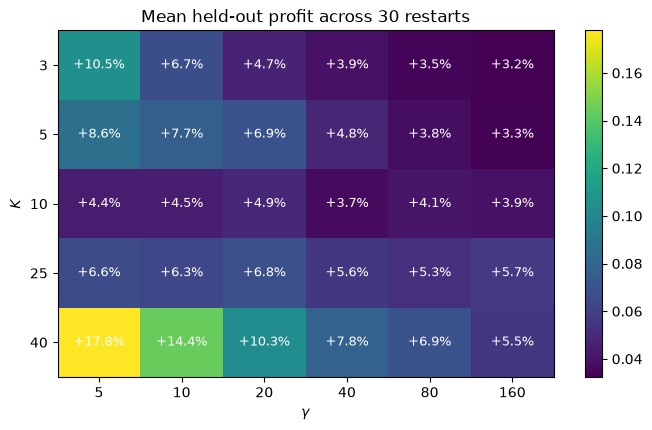

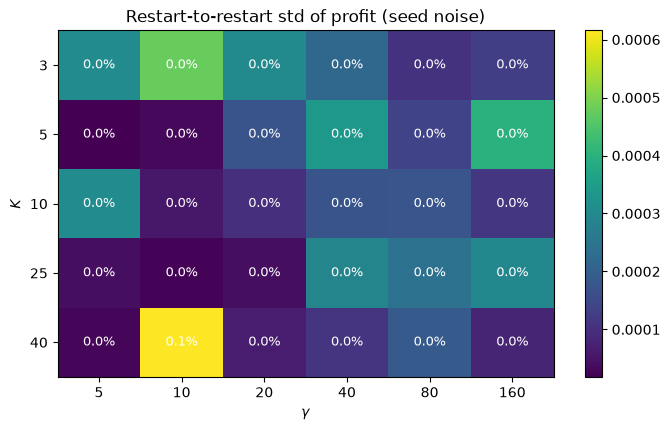

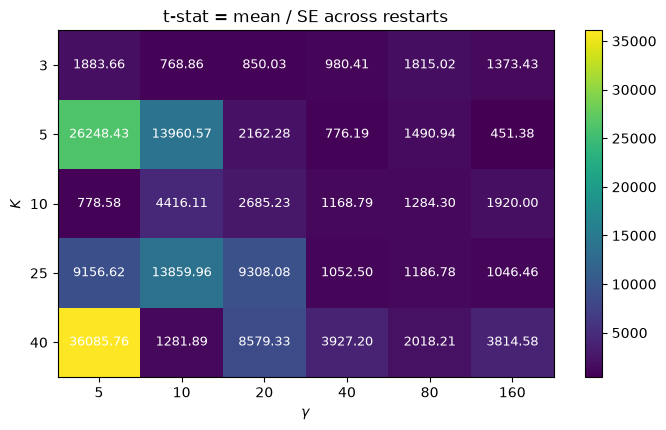

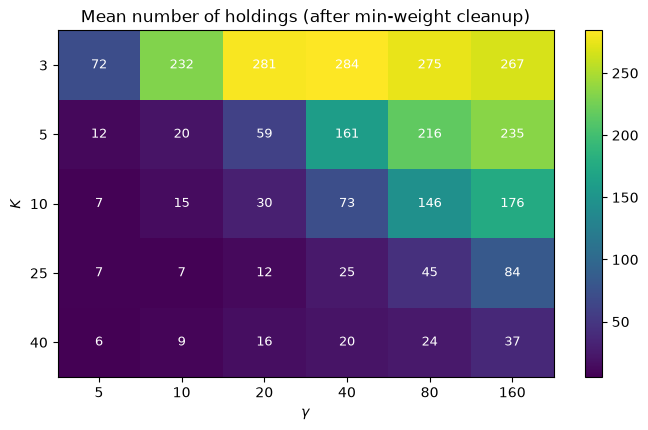

In [7]:
def heatmap(metric, title, fmt="{:.2f}"):
    pivot = results.pivot(index="K", columns="gamma", values=metric)[GAMMAS]
    pivot = pivot.loc[[k for k in KS if k in pivot.index]]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    im = ax.imshow(pivot.to_numpy(), cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(pivot.columns)), [f"{c:g}" for c in pivot.columns])
    ax.set_yticks(range(len(pivot.index)), [f"{i:g}" for i in pivot.index])
    ax.set_xlabel(r"$\gamma$")
    ax.set_ylabel("$K$")
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            ax.text(j, i, fmt.format(pivot.to_numpy()[i, j]),
                    ha="center", va="center", color="white", fontsize=9)
    ax.set_title(title)
    fig.colorbar(im, ax=ax)
    return fig

heatmap("profit_mean", "Mean held-out profit across 30 restarts", fmt="{:+.1%}")
heatmap("profit_std", "Restart-to-restart std of profit (seed noise)", fmt="{:.1%}")
heatmap("t_stat", "t-stat = mean / SE across restarts")
heatmap("holdings_mean", "Mean number of holdings (after min-weight cleanup)", fmt="{:.0f}")
plt.show()

## The winner on the held-out month

Cumulative return of the winning config's best-restart book vs the anchor config
($K=25, \gamma=40$) and 1/N, then the winner's top positions.

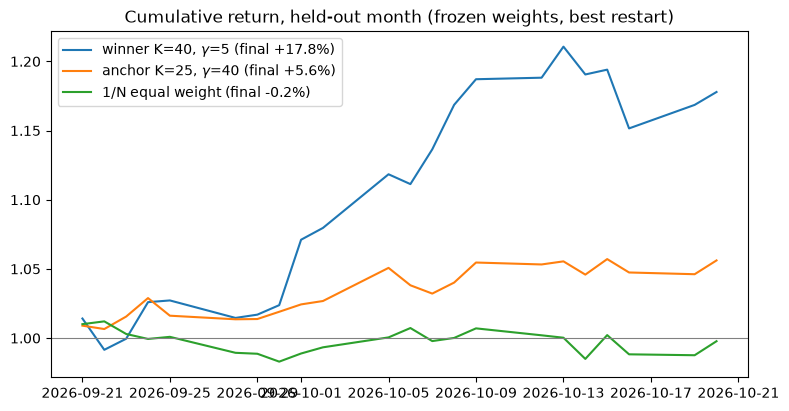

winner holds 5 names (mean across restarts: 6); top 15:


,weight
ticker,
MPC,0.393236
TEAM,0.292747
P,0.196609
MRNA,0.077133
OKTA,0.040275


In [8]:
anchor_key = (25, 40)
if anchor_key not in weights_by_cfg:
    anchor_key = (min(KS, key=lambda k: abs(k - 25)), min(GAMMAS, key=lambda g: abs(g - 40)))

fig, ax = plt.subplots(figsize=(9, 4.5))
for label, w in [
    (f"winner K={int(best.K)}, $\\gamma$={best.gamma:g}", weights_by_cfg[(int(best.K), best.gamma)]),
    (f"anchor K={anchor_key[0]}, $\\gamma$={anchor_key[1]:g}", weights_by_cfg[anchor_key]),
    ("1/N equal weight", pd.Series(w_1n, index=train.index)),
]:
    eq = (1 + full_vector(w, train.index) @ test.to_numpy()).cumprod()
    ax.plot(test.columns, eq, label=f"{label} (final {eq[-1] - 1:+.1%})")
ax.axhline(1.0, color="gray", lw=0.8)
ax.set_title("Cumulative return, held-out month (frozen weights, best restart)")
ax.legend()
plt.show()

print(f"winner holds {int(best.n_holdings)} names (mean across restarts: "
      f"{best.holdings_mean:.0f}); top 15:")
weights_by_cfg[(int(best.K), best.gamma)].head(15).to_frame("weight")

## Honest caveats

- **The t-stat only measures restart (seed) noise.** All 30 restarts share the same training
  and test windows; a $t \gtrsim 2$ config can still be a window fluke. Rolling the split over
  several months (walk-forward) is the principled next step.
- **Selection on the test set** makes the winner's numbers optimistic — this sweep is model
  *validation*, not an out-of-sample guarantee.
- **One test month.** 22 trading days is a small sample; adjacent months can rank $(\gamma, K)$
  differently.
- **$\hat\mu$ is the weak link.** `portfolio_oos_test` found 1/N beats every $\hat\mu$-using
  mean-variance book OOS on Sharpe; check the winner against the 1/N row above before
  believing it.
- The notebook's winner is fitted on the *train* window (ending a month ago); the production
  rerun command above refits on the **latest** 3 months via the CLI.
- A zero `profit_std` means all 30 restarts converged to (numerically) identical portfolios —
  typical for the diversified high-$\gamma$ corner, not a bug.